## **Σ estimation error and regularization**

To construct the unbiased sample covariance for an investment portfolio, we use the formula

$$S_{ij}=\frac{1}{T-1}\sum_{t=1}^{T}(r_{i,t}-\bar r_i)(r_{j,t}-\bar r_j)$$

which can be written in matrix notation as

$$S_{ij}=\frac{1}{T-1} X^T X$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Define a sample return matrix
return_matrix = np.array([
    [3, 7],
    [2, 4],
    [1, 4]
])

In [3]:
def sample_covariance(returns):
    #1. Number of assets
    T_obs = returns.shape[0]

    #2. Mean
    mu = returns.mean(axis=0, keepdims = True)

    # 3.Demeaned returns
    demeaned_returns = returns - mu

    #4. Sample covariance
    return (demeaned_returns.T @ demeaned_returns) / (T_obs - 1)

sample_covariance(return_matrix)

array([[1. , 1.5],
       [1.5, 3. ]])

**Construct a true $\Sigma$ with $N = 35$ (the size of the IPC) based on a one-factor model: $\Sigma = \sigma_m^2\beta\beta^\top + D$, using:**
- $\beta_i \sim U(0.5, 1.5)$
- $\sigma_m = 0.01$ (daily)
- idiosyncratic volatilities $\sim U(0.01, 0.02)$ on the diagonal of $D$
- seed 42.

In [4]:
seed = 42
rng = np.random.default_rng(seed)

N = 35

beta = rng.uniform(1,1.5, size=N)
sigma_m = 0.01
idio_vol = rng.uniform(0.01, 0.02, size=N)

Sigma = sigma_m**2 * np.outer(beta, beta) + np.diag(idio_vol**2)

(35, 35) True


<Axes: >

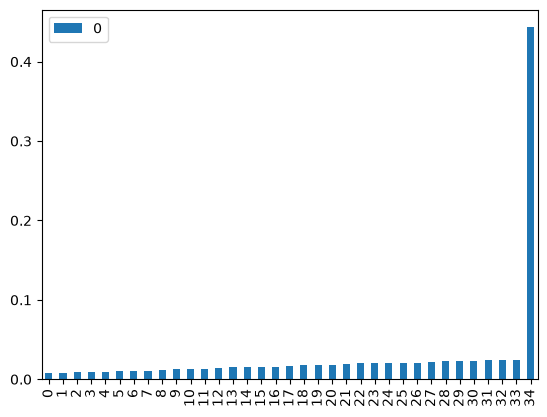

In [5]:
# Pruebas
print(Sigma.shape, np.allclose(Sigma, Sigma.T))

Sigma_eigs = np.linalg.eigvalsh(Sigma)
Sigma_eigs
participation = []
total_eigs = Sigma_eigs.sum()

for eig in Sigma_eigs:
    participation.append(eig / total_eigs)

participation = pd.DataFrame(participation)
participation.plot(kind="bar")


**For T $\in$ {30, 40, 60, 120, 250, 500, 1000, 5000}, perform 200 replications:**
- Simulate normal returns
- Estimate S and record the ordered eigenvalues
- λ_min
- λ_max
- Condition number
- Relative Frobenius error $\|S-\Sigma\|_F/\|\Sigma\|_F$.

In [6]:
# Lets begin with an example matrix
sigma_example = np.array([
    [4, 2],
    [2, 5]
])

In [7]:
# Define the shape of our returns matrix: T days, N assets
N = sigma_example.shape[0]
T = 100000

# 1. Apply Cholesky decomposition to the covariance matrix Sigma
L = np.linalg.cholesky(sigma_example)

Z = rng.standard_normal((T, N))

R = Z @ L.T

S = sample_covariance(R)

In [8]:
eigs = np.linalg.eigvalsh(S)

In [9]:
eigs = np.linalg.eigvalsh(S)
# Min and Max  eigenvalues
eig_min = eigs[0]
eig_max = eigs[-1]

# Condition number
condition_number = eig_max / eig_min

# Relative Frobenius error
rel_frobenius_error = np.linalg.norm(S - sigma_example, 'fro') / np.linalg.norm(sigma_example, 'fro')

### **Once we understand the process, we can build functions of it and begin the exercise**

In [10]:
def simulate_returns(Sigma, T, rng, mu=None):
    L = np.linalg.cholesky(Sigma) # 1. Apply Cholesky decomposition to the covariance matrix Sigma
    N = Sigma.shape[0]
    Z = rng.standard_normal((T, N)) # 2. Generate random noise. Mean 0, standard deviation 1
    R = Z @ L.T # 3. Compute the returns

    if mu is not None:
        R = R + mu

    return R

In [11]:
def spectrum_stats(S):
    """
    Inputs a covariance matrix
    Returns the spectrum stats in the following order:
    Ordered eigenvalues, Min eigenvalue, Max eigenvalue, Condition number
    """
    eigs = np.linalg.eigvalsh(S)
    eig_min, eig_max = eigs[0], eigs[-1]
    tol = eig_max * S.shape[0] * np.finfo(float).eps
    condition_number = np.inf if eig_min <= tol else eig_max / eig_min
    
    return eigs, eig_min, eig_max, condition_number


In [12]:
def relative_frobenius_error(Sigma, S):
    """
    Inputs a true covariance matrix and an estimation
    Outputs the Relative Frobenius Error
    """
    return np.linalg.norm(S - Sigma, 'fro') / np.linalg.norm(Sigma, 'fro')

In [13]:
# 1. Define the basic info for the simulation
T_values= np.array([30, 40, 60, 120, 250, 500, 1000, 5000])
n_replications = 200
N = Sigma.shape[0]
eigs_dict = {}
metrics = []

In [ ]:
# 2. Begin the simulation
for t in T_values:
    # 1. Create a n_replications x N empty array
    eigs_dict[t] = np.empty((n_replications, N)) 
    for rep in range(n_replications):
        
        #2. Calculate the relevant metrics
        R = simulate_returns(Sigma = Sigma, T = t, rng = rng)
        S = sample_covariance(R)
        eigs, eig_min, eig_max, condition_number = spectrum_stats(S)
        rel_frobenius_error = relative_frobenius_error(Sigma=Sigma, S=S)
        
        #3. Store the metrics in our dictionary or list. 1 dict/ list per t
        eigs_dict[t][rep, :] = eigs
        metrics_dict = {
            "T": t,
            "Replica": rep,
            "lambda_min": eig_min,
            "lambda_max": eig_max,
            "cond": condition_number,
            "frob_rel": rel_frobenius_error
        }
        metrics.append(metrics_dict)

In [ ]:
scalar_metrics = pd.DataFrame(metrics)

In [16]:
scalar_metrics.shape

(1600, 6)

In [ ]:
scalar_metrics.tail(20)

,T,Replica,lambda_min,lambda_max,cond,frob_rel
0,30,0,-2.428258e-19,0.006111,inf,0.348670
1,30,1,-3.613515e-19,0.005815,inf,0.371415
2,30,2,-3.733906e-19,0.004308,inf,0.480758
3,30,3,-2.710534e-19,0.005626,inf,0.425251
4,30,4,-4.281022e-19,0.008033,inf,0.486571
...,...,...,...,...,...,...
595,60,195,1.375041e-05,0.007266,528.416152,0.321227
596,60,196,9.438652e-06,0.006183,655.078476,0.280813
597,60,197,1.089728e-05,0.007011,643.353813,0.333311
598,60,198,1.530990e-05,0.006307,411.949259,0.262274


**Create two plots.**
1. The spectrum of $S$ versus that of $\Sigma$ for $T = 60$ and $T = 1000$, on a logarithmic scale. 
2. The average condition number of $S$ against $T/N$, with a horizontal line at $k(\Sigma)$.

For the first figure, I need:
1. The 35 eigenvalues ​​of the original $\Sigma$
2. The average of the 35 eigenvalues ​​from the 200 replicates generated for T = 60
3. The average of the 35 eigenvalues ​​from the 200 replicates generated for T = 1000

In [19]:
# 1. Already exists as Sigma_eigs

# 2. Average of the 35 eigenvalues ​​from the 200 replicates performed for T = 60
eigs_mean_T60 = eigs_dict[60].mean(axis=0)

# 3. Average of the 35 eigenvalues ​​from the 200 replicates performed for T = 1,000
eigs_mean_T1000 =eigs_dict[1000].mean(axis=0)

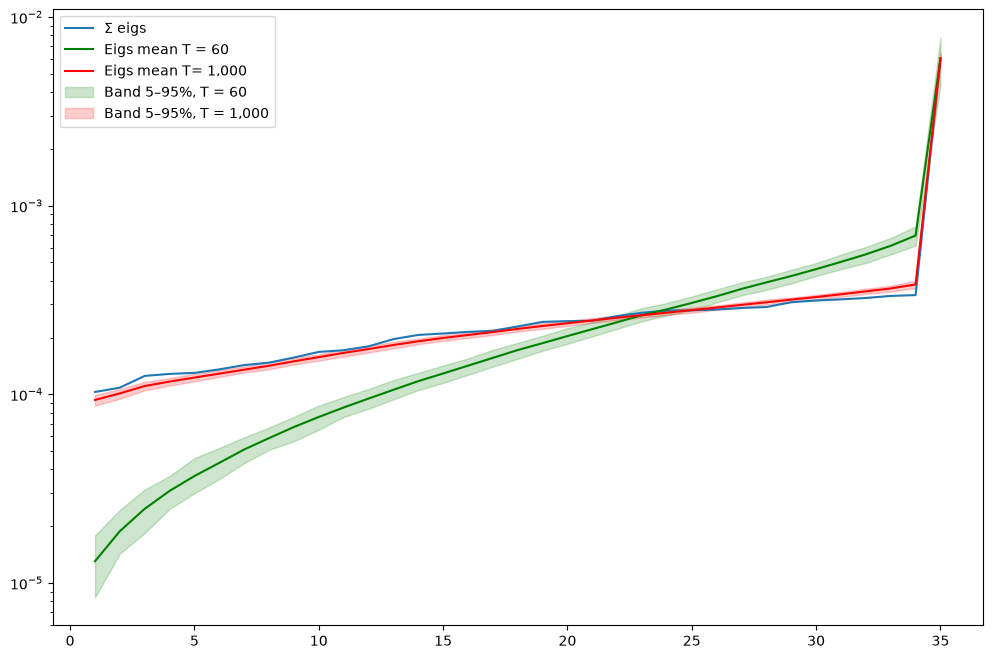

In [20]:
fig, ax = plt.subplots(figsize=(12,8))
x = list(range(1, N+1)) # X axis spanning our 35 eigenvalues
y1, y2, y3 = Sigma_eigs, eigs_mean_T60, eigs_mean_T1000 

# Compute the 90th percentile for T = 60 and  T = 1,000
T60_90_percentile = np.percentile(eigs_dict[60], [5, 95], axis=0) 
T1000_90_percentile = np.percentile(eigs_dict[1000], [5, 95], axis=0)
Sigma_90_percentile = np.percentile(Sigma_eigs, [5, 95], axis=0)

# Use semilogy to visualize the eigenvalues in log scale
ax.semilogy(x, y1, label='Σ eigs')
ax.semilogy(x, y2, color = 'green', label='Eigs mean T = 60')
ax.semilogy(x, y3, color = 'red', label='Eigs mean T= 1,000')

# Add a shaded band using the 5th and 95th percentiles of each column
T60_p5, T60_p95 = np.percentile(eigs_dict[60], [5, 95], axis=0)
ax.fill_between(x, T60_p5, T60_p95, color='green', alpha=0.2, label='Band 5–95%, T = 60')

T1000_p5, T1000_p95 = np.percentile(eigs_dict[1000], [5, 95], axis=0)
ax.fill_between(x, T1000_p5, T1000_p95, color='red', alpha=0.2, label='Band 5–95%, T = 1,000')
plt.legend()
plt.show()